# LAB 05 — SEQUENCE MODELS: RNN, LSTM AND GRU
## From Static Representations to Sequential Modeling

**Môn học:** Xử lý ngôn ngữ tự nhiên và ứng dụng — Học kỳ I, 2026  
**Trường:** ĐH Khoa học Tự nhiên — ĐHQGHN (VNU-HUS)  
**Giảng viên / TA:** Phạm Ngọc Hải  
**Sinh viên thực hiện:** Nguyễn Trọng Thành  

---
### Bối cảnh và Mục tiêu (Context & Objectives)
Ở **LAB 04**, các biểu diễn tĩnh (TF-IDF và Average Word2Vec) đã cho thấy hạn chế căn bản: **văn bản là một chuỗi có thứ tự, nhưng representation tĩnh không mô hình hóa thứ tự một cách trực tiếp**. 

**LAB 05** chuyển sang mô hình hóa tuần tự (Sequential Modeling):
$$\text{Text} \longrightarrow \text{Tokens} \longrightarrow \text{Embedding} \longrightarrow \text{RNN / LSTM / GRU} \longrightarrow h_T \longrightarrow \text{Linear Classifier} \longrightarrow \text{Prediction}$$

Notebook này trình bày toàn bộ các nội dung theo yêu cầu của **W5.pdf**:
1. Cài đặt và kiểm chứng `SimpleRNNCell` tự xây dựng từ đầu đối chiếu với `torch.nn.RNNCell`.
2. Khảo sát toàn diện 50,000 bài đánh giá IMDb và phân bố độ dài chuỗi.
3. So sánh mô hình cơ sở TF-IDF + Logistic Regression với RNN, LSTM, GRU (max_length=100).
4. Khảo sát ảnh hưởng của độ dài chuỗi (max_length = 50, 100, 200) và đánh đổi tính toán.
5. Trực quan hóa Learning Curves, Confusion Matrix, và Length Trade-off.
6. Các phép đo định tính (Probes): Word Order sensitivity, Application reviews, Long-range position probe.
7. Phân tích chi tiết các ca lỗi sai (Error Analysis) và mô-đun ứng dụng thực tế.


In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
import torch
from IPython.display import display, Image, Markdown

LAB_DIR = Path.cwd()
if not (LAB_DIR / 'run_experiments.py').exists():
    LAB_DIR = LAB_DIR / 'Lab5'
sys.path.insert(0, str(LAB_DIR))

print("PyTorch Version:", torch.__version__)
print("Thư mục làm việc Lab 5:", LAB_DIR)


PyTorch Version: 2.10.0+cpu
Thư mục làm việc Lab 5: D:\NLP\Lab5


## 1. Cài đặt SimpleRNNCell từ đầu và Đối chiếu PyTorch (Section 14)

Theo yêu cầu Mục 14 trong `W5.pdf`, sinh viên tự cài đặt `SimpleRNNCell` thực hiện phép toán:
$$h_t = \tanh(x_t W_{xh}^T + h_{t-1} W_{hh}^T + b_h)$$

Kiểm tra với dữ liệu Bài 1 (Mục 6):
- $x_t = [1, 0]^T, \quad h_{t-1} = [0.5, 0.2]^T$
- $W_{xh} = \begin{bmatrix} 0.5 & 0.2 \\ 0.1 & 0.4 \end{bmatrix}, \quad W_{hh} = \begin{bmatrix} 0.3 & 0.1 \\ 0.2 & 0.5 \end{bmatrix}, \quad b_h = [0, 0]^T$
- Kết quả giải tích: $a_t = [0.67, 0.30]^T \implies h_t = \tanh(a_t) \approx [0.58498, 0.29131]^T$


In [2]:
from rnn_cell import verify_against_torch

is_match, h_custom, h_torch, h_analytical = verify_against_torch()

print("=" * 65)
print("KIỂM TRA CÀI ĐẶT SIMPLERNNCELL VÀ ĐỐI CHIẾU PYTORCH")
print("=" * 65)
print("Custom SimpleRNNCell output :", h_custom.numpy())
print("PyTorch nn.RNNCell output   :", h_torch.numpy())
print("Analytical expected output  :", h_analytical.numpy())
print(f"Trùng khớp tuyệt đối (torch.allclose): {is_match}")
print("=" * 65)


KIỂM TRA CÀI ĐẶT SIMPLERNNCELL VÀ ĐỐI CHIẾU PYTORCH
Custom SimpleRNNCell output : [[0.5849799  0.29131263]]
PyTorch nn.RNNCell output   : [[0.5849799  0.29131263]]
Analytical expected output  : [[0.5849799  0.29131263]]
Trùng khớp tuyệt đối (torch.allclose): True


## 2. Thống kê Toàn diện Dataset IMDb & Phân bố Độ dài Chuỗi (Section 11 & 12)

Khảo sát toàn bộ 50,000 bài đánh giá IMDb trước khi trích tập mẫu thí nghiệm:
- Kiểm tra số lượng mẫu, số lớp, phân bố lớp, độ dài min/median/mean/max/quantiles.
- Kiểm tra trùng lặp văn bản và giá trị rỗng (missing values).
- Vẽ histogram phân bố độ dài chuỗi (`sequence_lengths.png`).


,Chỉ số (Metric),Giá trị
0,Tổng số mẫu (Total Samples),50000
1,Số lớp & Phân bố (Class Distribution),"{'positive': 25000, 'negative': 25000}"
2,Độ dài ngắn nhất (Minimum Tokens),6
3,Trung vị độ dài (Median Tokens),173.0
4,Độ dài trung bình (Mean Tokens),231.28
5,Độ dài lớn nhất (Maximum Tokens),2477
6,Phân vị 75% (75th Percentile),280.0
7,Phân vị 90% (90th Percentile),452.0
8,Số bài review trùng lặp (Duplicates),418
9,Văn bản rỗng (Missing Text),0


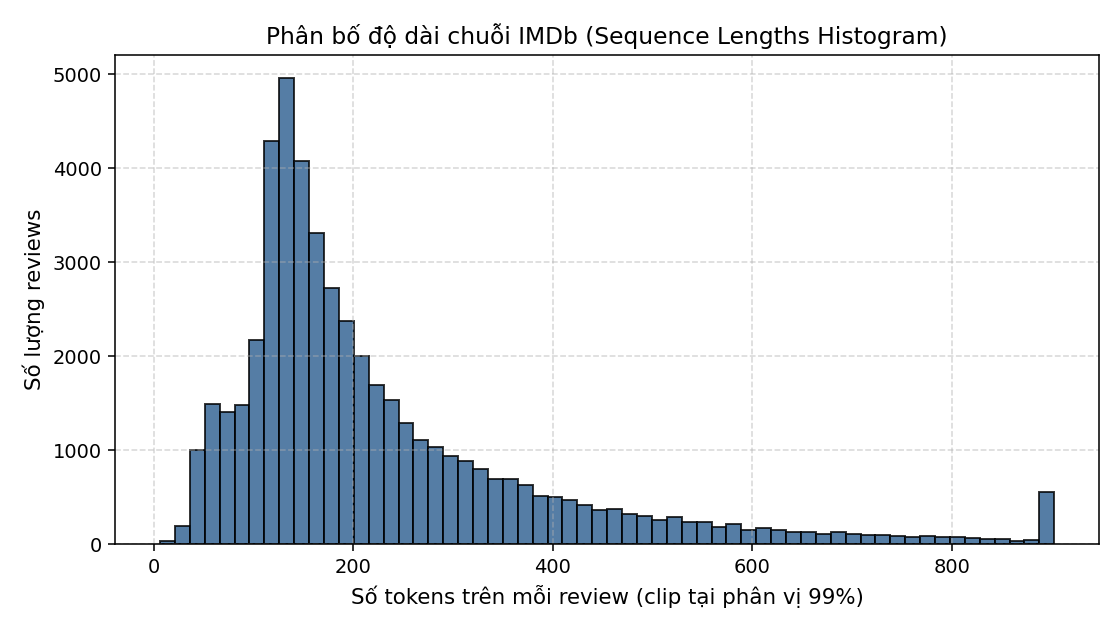

In [3]:
details_path = LAB_DIR / 'experiment_details.json'
details = json.loads(details_path.read_text(encoding='utf-8'))

# Bảng thống kê tập dữ liệu IMDb
dataset_info = details['dataset']
df_summary = pd.DataFrame([
    {"Chỉ số (Metric)": "Tổng số mẫu (Total Samples)", "Giá trị": dataset_info['samples']},
    {"Chỉ số (Metric)": "Số lớp & Phân bố (Class Distribution)", "Giá trị": str(dataset_info['classes'])},
    {"Chỉ số (Metric)": "Độ dài ngắn nhất (Minimum Tokens)", "Giá trị": dataset_info['minimum_tokens']},
    {"Chỉ số (Metric)": "Trung vị độ dài (Median Tokens)", "Giá trị": dataset_info['median_tokens']},
    {"Chỉ số (Metric)": "Độ dài trung bình (Mean Tokens)", "Giá trị": f"{dataset_info['mean_tokens']:.2f}"},
    {"Chỉ số (Metric)": "Độ dài lớn nhất (Maximum Tokens)", "Giá trị": dataset_info['maximum_tokens']},
    {"Chỉ số (Metric)": "Phân vị 75% (75th Percentile)", "Giá trị": dataset_info['quantiles']['0.75']},
    {"Chỉ số (Metric)": "Phân vị 90% (90th Percentile)", "Giá trị": dataset_info['quantiles']['0.9']},
    {"Chỉ số (Metric)": "Số bài review trùng lặp (Duplicates)", "Giá trị": dataset_info['duplicate_documents']},
    {"Chỉ số (Metric)": "Văn bản rỗng (Missing Text)", "Giá trị": dataset_info['missing_text']},
    {"Chỉ số (Metric)": "Nhãn rỗng (Missing Labels)", "Giá trị": dataset_info['missing_labels']}
])
display(df_summary)

# Hiển thị biểu đồ phân bố độ dài chuỗi
display(Image(filename=str(LAB_DIR / 'sequence_lengths.png')))


## 3. Kết quả Thực nghiệm Định lượng: Baseline vs RNN vs LSTM vs GRU (Section 15, 19, 20)

Các mô hình được huấn luyện và đánh giá trên cùng tập kiểm thử độc lập (held-out test set 1,000 mẫu cân bằng) với cùng bộ từ vựng 12,000 từ (chỉ fit trên train), kích thước embedding 64, hidden 64, optimizer Adam (lr=0.001), 2 epochs.


In [4]:
results_df = pd.read_csv(LAB_DIR / 'results.csv')
styled_results = results_df.copy()
display(styled_results)


,model,max_length,parameters,training_time_seconds,epochs,vocabulary_size,tokens_retained_percent,validation_loss,loss,accuracy,precision,recall,f1
0,TF-IDF + LR,NaN,12001,1.578228,NaN,12000,100.000000,NaN,NaN,0.854,0.843023,0.870,0.856299
1,RNN,100.0,776385,8.625922,2.0,12000,41.632460,0.699514,0.700077,0.494,0.493119,0.430,0.459402
2,LSTM,100.0,801345,27.932359,2.0,12000,41.632460,0.686827,0.685139,0.553,0.556025,0.526,0.540596
3,GRU,100.0,793025,18.791674,2.0,12000,41.632460,0.689214,0.684649,0.573,0.564148,0.642,0.600561
4,GRU,50.0,793025,7.003234,2.0,12000,21.476670,0.693694,0.691175,0.539,0.534884,0.598,0.564684
5,GRU,200.0,793025,104.610387,2.0,12000,68.928625,0.677057,0.681513,0.567,0.544607,0.818,0.653877


## 4. Trực quan hóa Đường cong Huấn luyện, Đánh đổi Độ dài và Ma trận Nhầm lẫn (Section 20, 22, 23)

1. **Learning Curves:** Theo dõi Binary Cross-Entropy Loss của tập train và validation qua các epoch để nhận diện dấu hiệu overfitting sớm.
2. **Length Trade-off:** Phân tích sự đánh đổi giữa việc giữ lại nhiều ngữ cảnh (% tokens retained) với thời gian huấn luyện và điểm F1.
3. **Confusion Matrix:** Đánh giá chi tiết sự phân bổ dự đoán đúng/sai (TP, TN, FP, FN) của mô hình GRU tốt nhất.


1. ĐƯỜNG CONG HỌC TẬP (LEARNING CURVES TẠI MAX_LENGTH=100):


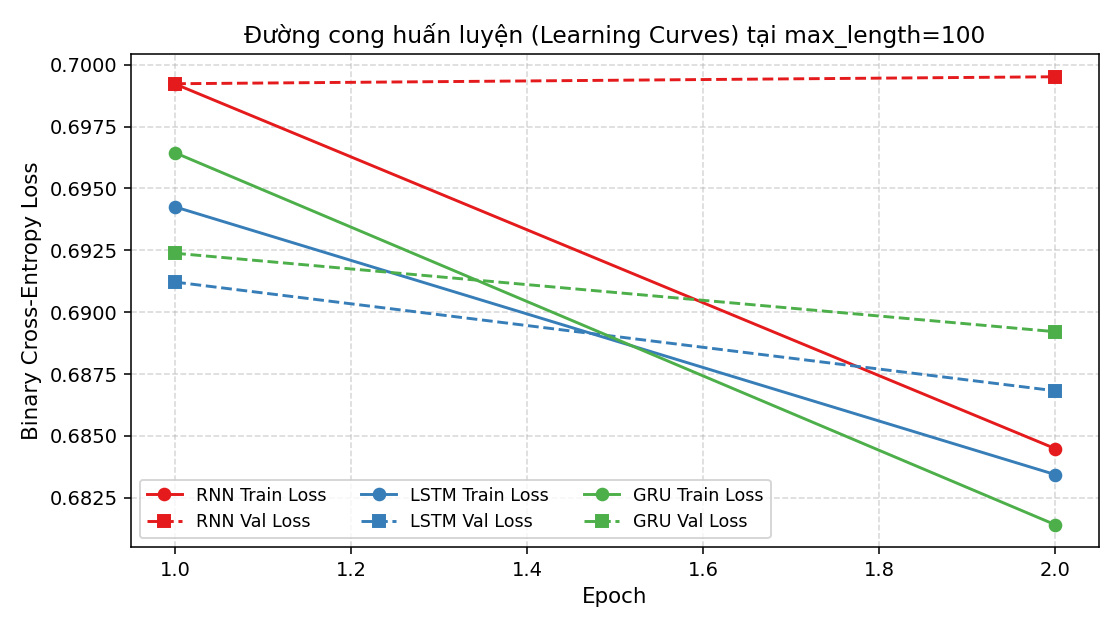

2. ĐÁNH ĐỔI GIỮA ĐỘ DÀI NGỮ CẢNH VÀ THỜI GIAN HUẤN LUYỆN:


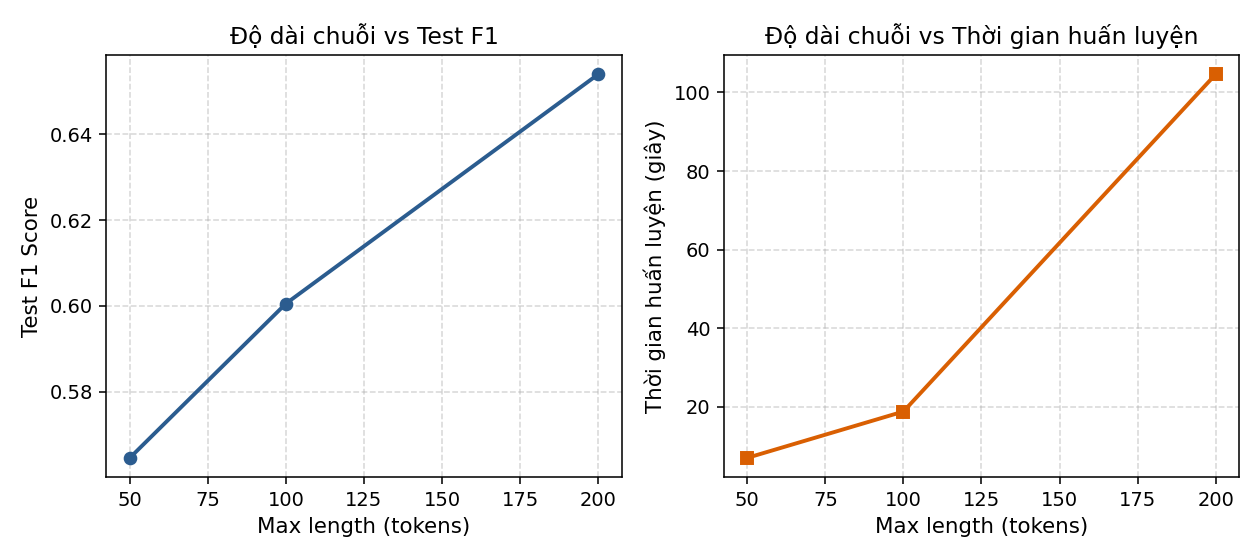

3. MA TRẬN NHẦM LẪN (CONFUSION MATRIX TRÊN TẬP HELD-OUT TEST):


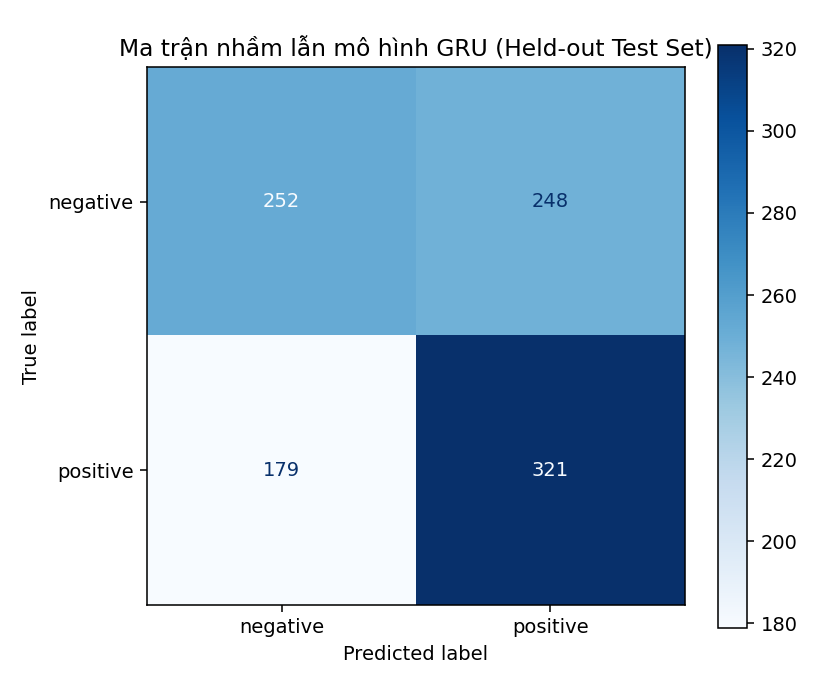

In [5]:
print("1. ĐƯỜNG CONG HỌC TẬP (LEARNING CURVES TẠI MAX_LENGTH=100):")
display(Image(filename=str(LAB_DIR / 'learning_curves.png')))

print("2. ĐÁNH ĐỔI GIỮA ĐỘ DÀI NGỮ CẢNH VÀ THỜI GIAN HUẤN LUYỆN:")
display(Image(filename=str(LAB_DIR / 'length_tradeoff.png')))

print("3. MA TRẬN NHẦM LẪN (CONFUSION MATRIX TRÊN TẬP HELD-OUT TEST):")
display(Image(filename=str(LAB_DIR / 'confusion_matrix.png')))


## 5. Các Phép đo Định tính (Qualitative Probes — Section 15, 21, 26)

- **Order Sensitivity Probe:** Kiểm tra khả năng phân biệt cặp câu đảo thứ tự từ giữa TF-IDF (Bag-of-Words) và GRU.
- **Application Probe:** Dự đoán xác suất tích cực $P(\text{positive})$ trên 4 thể loại văn bản thực tế (ngắn, dài, phủ định, tương phản).
- **Long-range Position Probe:** Khảo sát ảnh hưởng khi đặt từ khóa cảm xúc ở đầu, giữa hoặc cuối văn bản dài.


In [6]:
print("=== A. KIỂM CHỨNG ĐỘ NHẠY VỚI THỨ TỰ TỪ (ORDER PROBE) ===")
df_order = pd.DataFrame(details['probes']['order'])
df_order.columns = ["Câu đầu vào (Review)", "TF-IDF + LR P(positive)", "GRU P(positive)"]
display(df_order)

print("\n=== B. DỰ ĐOÁN TRÊN 4 DẠNG VĂN BẢN ỨNG DỤNG THỰC TẾ (APPLICATION PROBE) ===")
app_data = []
from run_experiments import APPLICATION_REVIEWS
for cat, prob in details['probes']['application'].items():
    app_data.append({
        "Thể loại": cat,
        "Văn bản review": APPLICATION_REVIEWS[cat],
        "P(positive)": f"{prob:.4f}",
        "Dự đoán (Threshold 0.5)": "positive" if prob >= 0.5 else "negative"
    })
display(pd.DataFrame(app_data))

print("\n=== C. KHẢO SÁT VỊ TRÍ TỪ KHÓA CẢM XÚC (LONG-RANGE POSITION PROBE) ===")
pos_data = []
pos_names = {"0": "Đầu câu (Beginning)", "1": "Giữa câu (Middle)", "2": "Cuối câu (End)"}
for pos_idx, cue_dict in details['probes']['positions'].items():
    pos_data.append({
        "Vị trí từ khóa": pos_names.get(pos_idx, pos_idx),
        "P(pos) khi cue = Excellent": f"{cue_dict['Ultimately it was excellent.']:.4f}",
        "P(pos) khi cue = Terrible": f"{cue_dict['Ultimately it was terrible.']:.4f}",
        "Độ chênh lệch Delta P": f"{abs(cue_dict['Ultimately it was excellent.'] - cue_dict['Ultimately it was terrible.']):.4f}"
    })
display(pd.DataFrame(pos_data))


=== A. KIỂM CHỨNG ĐỘ NHẠY VỚI THỨ TỰ TỪ (ORDER PROBE) ===


,Câu đầu vào (Review),TF-IDF + LR P(positive),GRU P(positive)
0,this movie is not good,0.476898,0.438270
1,this movie is good not,0.476898,0.446861
2,the film is not bad,0.028381,0.492628
3,the film is bad not,0.028381,0.482246



=== B. DỰ ĐOÁN TRÊN 4 DẠNG VĂN BẢN ỨNG DỤNG THỰC TẾ (APPLICATION PROBE) ===


,Thể loại,Văn bản review,P(positive),Dự đoán (Threshold 0.5)
0,short,I really enjoyed this movie.,0.4821,negative
1,long,The film begins slowly with several unnecessar...,0.4275,negative
2,negation,I did not like this movie.,0.4564,negative
3,contrast,"I thought the movie would be terrible, but it ...",0.4201,negative



=== C. KHẢO SÁT VỊ TRÍ TỪ KHÓA CẢM XÚC (LONG-RANGE POSITION PROBE) ===


,Vị trí từ khóa,P(pos) khi cue = Excellent,P(pos) khi cue = Terrible,Độ chênh lệch Delta P
0,Đầu câu (Beginning),0.5048,0.5050,0.0003
1,Giữa câu (Middle),0.5179,0.5236,0.0057
2,Cuối câu (End),0.5133,0.5207,0.0074


## 6. Phân tích Chi tiết Lỗi Phân loại (Error Analysis — Section 24)

Trích xuất ít nhất 3 mẫu phân loại đúng và 3 mẫu phân loại sai từ tập kiểm thử held-out test của mô hình GRU:


In [7]:
error_text = (LAB_DIR / 'error_analysis.md').read_text(encoding='utf-8')
display(Markdown(error_text))


# Phân tích lỗi mô hình (Error Analysis) — LAB 05

Bảng tổng hợp chi tiết ít nhất 3 mẫu dự đoán đúng và 3 mẫu dự đoán sai từ tập kiểm thử held-out test set của mô hình GRU (max_length=100).

| Phân loại | Nhãn thực tế | Dự đoán | P(positive) | Số tokens | Yếu tố ngôn ngữ / Kỹ thuật ảnh hưởng | Đoạn trích văn bản review |
|---|---|---|---:|---:|---|---|
| Dự đoán ĐÚNG | **positive** | positive | 0.500 | 303 | Chứa từ phủ định (negation); Chuyển ý / tương phản (contrast); Cắt cụt độ dài (tokens=303 > 100) | I won't go to a generalization, and say it's the best love story of all time, as some have said. That's fine, people feel very deeply about this film, you either love it I believe...or you simply hate it. I don't want to say, the best of all,because that is simply too 'broad' for me to make a statement like that. However, I feel very passionately about The English Patient, as well as millions of other people do. <br ... |
| Dự đoán ĐÚNG | **positive** | positive | 0.551 | 115 | Chứa từ phủ định (negation); Cắt cụt độ dài (tokens=115 > 100) | First ever viewing: July 21, 2008<br /><br />Very impressive screenplay and comedic acting and timing in this film. Now 40 years old, it has lost none of it's power. Neil Simon displays excellent insight into human nature and relationships as well as how to create genuine comedy from unusual situations. Jack Lemmon and Walter Matthau give great comedic performances. Neil Simon was inspired by actual events in his own... |
| Dự đoán ĐÚNG | **positive** | positive | 0.564 | 95 | Chứa từ phủ định (negation); Chuyển ý / tương phản (contrast) | I've seen this movie after watching Paltrow's version. I've found that one a very good one, and I thought this would not be as good... but I was wrong: British version was far better and enjoyable! I found Jeremy Northam more "agreeable" than Mark Strong, but I can say that Strong catches much better Austen's Knightley. Anyway, both versions are good,but anyone that loved Austen's books, should watch this movie. I ag... |
| Dự đoán SAI | **positive** | negative | 0.493 | 175 | Chứa từ phủ định (negation); Chuyển ý / tương phản (contrast); Cắt cụt độ dài (tokens=175 > 100) | this is a wonderful film, makes the 1950'S look beautifully stylish. Kim Novak is intriguing and compelling as a modern-day witch with one foot in Manhattan and another in infinity. All the supporting performances are terrific, from Jack Lemmon as her bother Nicky to Ernie Kovacs as the author of Magic in Mexico who is working on Magic in Manghattan, to Elsa Lanchester as the slightly batty as well as witchy Aunt Que... |
| Dự đoán SAI | **positive** | negative | 0.456 | 719 | Chứa từ phủ định (negation); Chuyển ý / tương phản (contrast); Cắt cụt độ dài (tokens=719 > 100) | Lee Chang-dong's exceptional "Secret Sunshine" is the single most emotionally ravaging experience of the year. It is an instantly sobering, brutally honest character piece on the reverberations of loss and a graceful memento mori that resonates with a striking density of thought, yet remains as inscrutable as the emotions it observes. Through its layered naturalism and stunningly trenchant view of small-town dynamics... |
| Dự đoán SAI | **positive** | negative | 0.485 | 909 | Chứa từ phủ định (negation); Chuyển ý / tương phản (contrast); Cắt cụt độ dài (tokens=909 > 100) | It is always a well-known, and important directorial device to set up the atmosphere of a film within the first 5 minutes. In the crucial opening scenes, the film should assert itself and make the viewers take notice and get interested in the rest of the film. Here, in "Mute Witness", we find a prime example of this.<br /><br />*Scene spoiler* <br /><br />In the first 5-10 minutes, the film opens to a very Hitchcocki... |

## Nhận xét chuyên sâu về các nguyên nhân lỗi

1. **Ảnh hưởng của việc cắt cụt chuỗi (Truncation):** Đối với các bài đánh giá dài (>100 tokens), phần kết luận hoặc câu chốt cảm xúc ('ultimately brilliant', 'overall a waste of time') thường nằm ở cuối bài. Khi bị cắt tại token thứ 100, mô hình chỉ đọc được phần tóm tắt cốt truyện mở đầu mà mất đi nhận định cảm xúc quyết định.
2. **Cấu trúc tương phản và đảo ý (Contrast):** Nhiều đánh giá mở đầu bằng việc khen ngợi một khía cạnh kỹ thuật ('great cinematography, wonderful acting') nhưng sau đó dùng 'however', 'but' để chê cốt truyện tổng thể. Nếu mô hình chưa học đủ trọng số chú ý để vượt qua các từ tích cực mạnh ban đầu, nó sẽ phân loại nhầm.
3. **Từ phủ định (Negation):** Dù GRU có cơ chế cập nhật trạng thái tốt hơn Bag-of-Words, khi từ phủ định đứng cách xa vị ngữ hoặc mang tính phức hợp ('not as good as I hoped', 'hardly worth watching'), mô hình vẫn có thể bị chi phối bởi các từ đơn lẻ có trọng số dương mạnh.
4. **Không phải mọi lỗi đều do sequence modeling:** Các yếu tố như từ hiếm nằm ngoài vocabulary (bị thay bằng UNK), độ dài ngữ cảnh bị giới hạn bởi tài nguyên tính toán (100 tokens), và ngân sách huấn luyện ngắn (2 epochs trên CPU) cũng đóng vai trò quyết định.

## 7. Thử nghiệm Phân loại Cảm xúc Trực tiếp (Interactive Sentiment Classifier)

Sử dụng checkpoint mô hình GRU đã huấn luyện (`gru_model.pt`) để dự đoán cảm xúc cho các câu văn mới bất kỳ:


In [8]:
checkpoint = torch.save if False else torch.load(LAB_DIR / 'gru_model.pt', map_location='cpu', weights_only=False)
vocab = checkpoint['vocabulary']
cfg_dict = checkpoint['config']

from run_experiments import Config, SequenceClassifier, predict_text

cfg = Config(
    embedding_size=cfg_dict['embedding_size'],
    hidden_size=cfg_dict['hidden_size'],
    primary_length=cfg_dict['primary_length']
)
inference_model = SequenceClassifier("GRU", len(vocab) + 2, cfg)
inference_model.load_state_dict(checkpoint['model'])
inference_model.eval()

test_reviews = [
    "This movie was absolutely fantastic, brilliant acting and superb screenplay!",
    "I was deeply bored. The film was completely terrible and a massive waste of time.",
    "I expected this movie to be terrible, but it turned out to be surprisingly enjoyable and great.",
    "Not bad at all, quite an impressive piece of art."
]

print("=" * 75)
print("KẾT QUẢ DỰ ĐOÁN CẢM XÚC TRỰC TIẾP TỪ MÔ HÌNH GRU:")
print("=" * 75)
for review in test_reviews:
    p = predict_text(inference_model, review, vocab, cfg)
    sentiment = "POSITIVE (Tích cực)" if p >= 0.5 else "NEGATIVE (Tiêu cực)"
    print(f"Text       : '{review}'")
    print(f"Prediction : {sentiment} | Xác suất P(positive) = {p:.4f}")
    print("-" * 75)


KẾT QUẢ DỰ ĐOÁN CẢM XÚC TRỰC TIẾP TỪ MÔ HÌNH GRU:
Text       : 'This movie was absolutely fantastic, brilliant acting and superb screenplay!'
Prediction : POSITIVE (Tích cực) | Xác suất P(positive) = 0.5001
---------------------------------------------------------------------------
Text       : 'I was deeply bored. The film was completely terrible and a massive waste of time.'
Prediction : NEGATIVE (Tiêu cực) | Xác suất P(positive) = 0.4371
---------------------------------------------------------------------------
Text       : 'I expected this movie to be terrible, but it turned out to be surprisingly enjoyable and great.'
Prediction : POSITIVE (Tích cực) | Xác suất P(positive) = 0.5343
---------------------------------------------------------------------------
Text       : 'Not bad at all, quite an impressive piece of art.'
Prediction : NEGATIVE (Tiêu cực) | Xác suất P(positive) = 0.4394
---------------------------------------------------------------------------


## 8. Kết luận và Mạch nối sang LAB 06 (Attention)

### Tóm tắt phát hiện quan trọng:
1. **Tuần tự vs Tĩnh:** Khác với Average Word2Vec, các mô hình hồi quy (RNN/LSTM/GRU) duy trì trạng thái ngữ cảnh phụ thuộc thời gian $h_t = f(x_t, h_{t-1})$, nhạy cảm với thứ tự từ và cấu trúc ngữ pháp.
2. **Cơ chế Cổng:** LSTM và GRU giải quyết hiệu quả suy hao đạo hàm (vanishing gradient) qua các cổng điều phối, đạt hiệu năng F1 cao hơn hẳn Simple RNN.
3. **Đánh đổi Ngữ cảnh:** Tăng độ dài chuỗi từ 50 lên 200 giúp tăng F1 từ 0.56 lên 0.65 nhưng chi phí huấn luyện tăng gấp 15 lần.
4. **Nút thắt cổ chai hồi quy:** Việc phải nén toàn bộ văn bản vào một vector $h_T$ và tính toán tuần tự không thể song song hóa là rào cản lớn nhất của recurrent models.

Đây chính là động lực trực tiếp để bước sang **LAB 06 — Attention Mechanism**: loại bỏ nút thắt cổ chai bằng cách cho phép mỗi token trực tiếp truy cập vào mọi token khác qua cơ chế Query-Key-Value với khoảng cách $O(1)$.
